# 05 · Population, Land Cover and the Master Dataset

**Project:** Spatio-Temporal Prediction of Pluvial and Coastal Flood Risk in Lagos State, Nigeria  
**Notebook:** 05 of the series · **Author:** Utibe Bassey

## Purpose

Flood risk is not just about **hazard** (rain and low ground); it is also about **surface runoff** (how much concrete and roofing blocks water from soaking into the soil) and **exposure** (how many people live in harm's way).

This notebook completes **Phase 2 (Data Collection & Cleaning)** by:
1. Extracting **10 m land cover shares** for each Lagos LGA from **ESA WorldCover (v200)** via Google Earth Engine (built-up impervious surfaces, wetlands/mangroves, vegetation/trees, and bare ground).
2. Extracting **annual population counts and density (2010–2025)** for each LGA from **WorldPop (100 m)** via Google Earth Engine (`WorldPop/GP/100m/pop` for 2010–2014 and `WorldPop/GP/100m/R2025A/v1/pop` for 2015–2025, harmonised at the 2015 overlap).
3. Merging all four cleaned datasets (`flood_labels_lga_month.csv`, `rainfall_lga_month.csv`, `terrain_water_lga.csv`, and `population_landcover_lga_year.csv`) into one **master LGA-by-month table** (`data/clean/master_lga_month.csv`, 3,840 rows).
4. Running strict completeness, schema, and range assertions, and generating a complete **Data Dictionary** (`data/clean/data_dictionary.csv`).

## Inputs and outputs

| | File | Notes |
| --- | --- | --- |
| **Input** | `data/clean/lagos_lgas.gpkg` | 20 Lagos LGA boundaries (Notebook 01) |
| **Input** | `data/clean/rainfall_lga_month.csv` | Monthly & antecedent CHIRPS rainfall features (Notebook 02) |
| **Input** | `data/clean/terrain_water_lga.csv` | SRTM elevation, slope & JRC distance to water (Notebook 03) |
| **Input** | `data/clean/flood_labels_lga_month.csv` | Documented flood occurrence labels (Notebook 04) |
| **Output** | `data/clean/landcover_lga.csv` | ESA WorldCover 10 m land-cover shares per LGA (20 rows) |
| **Output** | `data/clean/population_lga_year.csv` | Annual population & density per LGA, 2010–2025 (320 rows) |
| **Output** | `data/clean/master_lga_month.csv` | **Master modelling dataset** (3,840 rows) |
| **Output** | `data/clean/data_dictionary.csv` | Full column-by-column documentation |

## 1. Setup

In [1]:
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import ee

In [2]:
PROJECT_ID = "lagos-flood-risk"

LGA_PATH = Path("../data/clean/lagos_lgas.gpkg")
RAIN_PATH = Path("../data/clean/rainfall_lga_month.csv")
TERRAIN_PATH = Path("../data/clean/terrain_water_lga.csv")
LABELS_PATH = Path("../data/clean/flood_labels_lga_month.csv")

LANDCOVER_PATH = Path("../data/clean/landcover_lga.csv")
POP_PATH = Path("../data/clean/population_lga_year.csv")
MASTER_PATH = Path("../data/clean/master_lga_month.csv")
DICT_PATH = Path("../data/clean/data_dictionary.csv")

LANDCOVER_SCALE_M = 30   # 30 m aggregation of 10 m ESA WorldCover keeps GEE requests fast and exact at LGA scale
POP_SCALE_M = 100        # WorldPop native resolution (100 m)

## 2. Connect to Earth Engine and compute LGA land areas

In [3]:
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)
print("Connected to Earth Engine")

lagos = gpd.read_file(LGA_PATH)
# Compute total geographic area (km2) in metric CRS UTM Zone 31N (EPSG:32631)
lagos_utm = lagos.to_crs("EPSG:32631")
lagos["total_area_km2"] = (lagos_utm.geometry.area / 1e6).round(2)

# Simplify slightly for Earth Engine upload
lagos_simple = lagos[["lga", "geometry"]].copy()
lagos_simple["geometry"] = lagos_simple.geometry.simplify(0.001, preserve_topology=True)
lagos_fc = ee.FeatureCollection(json.loads(lagos_simple.to_json())["features"])
print("Loaded 20 Lagos LGAs. Total state area (km2):", round(lagos["total_area_km2"].sum(), 1))

Connected to Earth Engine
Loaded 20 Lagos LGAs. Total state area (km2): 3782.0


### Interpretation: LGA geographic sizes
Lagos State spans roughly 3,500–3,600 $\text{km}^2$ including its lagoons and creeks, but the 20 LGAs vary dramatically in size: **Ibeju-Lekki**, **Epe**, **Badagry**, and **Ikorodu** are vast peri-urban/coastal corridors, whereas central urban LGAs like **Lagos Island**, **Ajeromi/Ifelodun**, **Apapa**, **Mushin**, and **Shomolu** are compact and densely built.

## 3. Extract Land Cover from ESA WorldCover (10 m)

**ESA WorldCover v200 (2021)** classifies the land surface at 10 m resolution using Sentinel-1 and Sentinel-2 imagery:
- **Class 50 (`built_share`)**: Built-up (buildings, roads, concrete). Impervious surfaces stop rain from infiltrating into the ground, turning heavy rain directly into surface runoff.
- **Classes 90 & 95 (`wetland_mangrove_share`)**: Herbaceous wetland (90) and Mangroves (95). These indicate natural floodplains, swamps, and tidal marshes.
- **Classes 10, 20, 30, 40 (`veg_share`)**: Tree cover, shrubland, grassland, and cropland (permeable vegetated surfaces).
- **Class 60 (`bare_share`)**: Bare or sparse vegetation (sand, cleared land, coastal beaches).

We mask out permanent open water (Class 80) when computing **shares of land**, so that `built_share` measures the fraction of *land* in each LGA that is paved or built over.

In [4]:
if LANDCOVER_PATH.exists():
    landcover = pd.read_csv(LANDCOVER_PATH)
    print("Loaded cached landcover:", LANDCOVER_PATH.resolve())
else:
    wc = ee.ImageCollection("ESA/WorldCover/v200").first().select("Map")
    not_water_wc = wc.neq(80)   # 1 on non-water pixels, 0 on open water (Class 80)

    lc_bands = ee.Image.cat([
        wc.eq(50).updateMask(not_water_wc).rename("built_share"),
        wc.eq(90).Or(wc.eq(95)).updateMask(not_water_wc).rename("wetland_mangrove_share"),
        wc.eq(10).Or(wc.eq(20)).Or(wc.eq(30)).Or(wc.eq(40)).updateMask(not_water_wc).rename("veg_share"),
        wc.eq(60).updateMask(not_water_wc).rename("bare_share"),
    ])

    lc_props = ["built_share", "wetland_mangrove_share", "veg_share", "bare_share"]
    fc_lc = lc_bands.reduceRegions(
        collection=lagos_fc,
        reducer=ee.Reducer.mean(),
        scale=LANDCOVER_SCALE_M,
        tileScale=4,
    ).select(["lga"] + lc_props, None, False)

    rows_lc = fc_lc.getInfo()["features"]
    landcover = pd.DataFrame([r["properties"] for r in rows_lc]).sort_values("lga").reset_index(drop=True)
    landcover[lc_props] = landcover[lc_props].round(3)
    landcover.to_csv(LANDCOVER_PATH, index=False)
    print("Saved:", LANDCOVER_PATH.resolve())

lc_props = ["built_share", "wetland_mangrove_share", "veg_share", "bare_share"]
assert len(landcover) == 20
assert landcover[lc_props].notna().all().all()
for col in lc_props:
    assert landcover[col].between(0, 1).all(), f"{col} out of [0,1] bounds"

landcover.sort_values("built_share", ascending=False).head(10)

Loaded cached landcover: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\landcover_lga.csv


,bare_share,built_share,lga,veg_share,wetland_mangrove_share
0,0.000,0.983,Agege,0.017,0.000
19,0.000,0.970,Surulere,0.029,0.001
15,0.001,0.965,Mushin,0.034,0.000
18,0.001,0.954,Shomolu,0.043,0.002
1,0.003,0.953,Ajeromi/Ifelodun,0.044,0.000
9,0.000,0.944,Ifako/Ijaye,0.056,0.000
14,0.002,0.899,Mainland,0.086,0.013
10,0.000,0.883,Ikeja,0.116,0.000
2,0.006,0.822,Alimosho,0.161,0.011
17,0.001,0.814,Oshodi/Isolo,0.185,0.000


### Analysis of Land Cover across Lagos LGAs
The table above reveals a striking urban-to-peri-urban gradient:
- **Core Metropolitan LGAs** (**Mushin**, **Ajeromi/Ifelodun**, **Agege**, **Shomolu**, **Lagos Island**, **Surulere**, **Oshodi/Isolo**, **Mainland**, and **Ikeja**) have very high `built_share` (often $>75\%$ to $95\%$ of all land paved or roofed). In these LGAs, virtually all rainfall must be evacuated by artificial drainage channels.
- **Lagoon & Riverine Corridor LGAs** (**Kosofe**, **Amuwo Odofin**, **Ikorodu**, **Apapa**, **Ojo**) combine substantial impervious cover with significant `wetland_mangrove_share`, meaning urban runoff flows straight into low-lying marshes and tidal creeks.
- **Outer Coastal & Eastern LGAs** (**Epe**, **Ibeju-Lekki**, **Badagry**) retain high `veg_share`, though rapid coastal development in **Eti-Osa** and **Ibeju-Lekki** is steadily replacing permeable ground.

## 4. Extract Annual Population (2010–2025) from WorldPop

To capture how urban growth increases flood exposure over time, we extract annual population counts for every LGA from 2010 to 2025:
- **2015–2025**: Extracted directly from the updated **`WorldPop/GP/100m/R2025A/v1/pop`** collection (which provides annual gridded population estimates and projections for Nigeria through 2030).
- **2010–2015**: Extracted from **`WorldPop/GP/100m/pop`**, and ratio-harmonised at the 2015 overlap year for each LGA so there is no artificial jump between the two WorldPop releases.
- **Land Area & Population Density**: Using `water_share` from Notebook 03, we compute each LGA's actual land area $\text{land\_area\_km2} = \text{total\_area\_km2} \times (1 - \text{water\_share})$ and its population density on land (`pop_density_km2`).

In [5]:
if POP_PATH.exists():
    pop_df = pd.read_csv(POP_PATH)
    print("Loaded cached population table:", POP_PATH.resolve())
else:
    wp_old = ee.ImageCollection("WorldPop/GP/100m/pop").filter(ee.Filter.eq("country", "NGA"))
    wp_new = ee.ImageCollection("WorldPop/GP/100m/R2025A/v1/pop").filter(ee.Filter.eq("country", "NGA"))

    def get_pop_year(collection, yr):
        img = collection.filter(ee.Filter.eq("year", int(yr))).first().select("population")
        fc = img.reduceRegions(
            collection=lagos_fc,
            reducer=ee.Reducer.sum(),
            scale=POP_SCALE_M,
            tileScale=4,
        ).select(["lga", "sum"], None, False)
        feats = fc.getInfo()["features"]
        df = pd.DataFrame([r["properties"] for r in feats]).rename(columns={"sum": "pop_raw"})
        df["year"] = int(yr)
        return df

    new_dfs = [get_pop_year(wp_new, yr) for yr in range(2015, 2026)]
    df_new = pd.concat(new_dfs, ignore_index=True)

    old_dfs = [get_pop_year(wp_old, yr) for yr in range(2010, 2016)]
    df_old = pd.concat(old_dfs, ignore_index=True)

    p2015_new = df_new[df_new["year"] == 2015].set_index("lga")["pop_raw"]
    p2015_old = df_old[df_old["year"] == 2015].set_index("lga")["pop_raw"]
    scale_factor = (p2015_new / p2015_old).rename("scale_2015").reset_index()

    df_old_pre2015 = df_old[df_old["year"] < 2015].merge(scale_factor, on="lga", how="left")
    df_old_pre2015["population"] = df_old_pre2015["pop_raw"] * df_old_pre2015["scale_2015"]
    df_new["population"] = df_new["pop_raw"]

    pop_df = pd.concat(
        [df_old_pre2015[["lga", "year", "population"]], df_new[["lga", "year", "population"]]],
        ignore_index=True,
    ).sort_values(["lga", "year"]).reset_index(drop=True)

    terrain_df = pd.read_csv(TERRAIN_PATH)
    area_df = lagos[["lga", "total_area_km2"]].merge(terrain_df[["lga", "water_share"]], on="lga", how="left")
    area_df["land_area_km2"] = (area_df["total_area_km2"] * (1.0 - area_df["water_share"])).clip(lower=1.0).round(2)

    pop_df = pop_df.merge(area_df[["lga", "total_area_km2", "land_area_km2"]], on="lga", how="left")
    pop_df["population"] = pop_df["population"].round(0).astype(int)
    pop_df["pop_density_km2"] = (pop_df["population"] / pop_df["land_area_km2"]).round(1)
    pop_df.to_csv(POP_PATH, index=False)
    print("Saved:", POP_PATH.resolve())

assert len(pop_df) == 20 * 16, f"Expected 320 LGA-year rows, got {len(pop_df)}"
assert pop_df.notna().all().all()
assert (pop_df["population"] > 0).all()

print("Total Lagos gridded population (2010):", f"{pop_df[pop_df['year']==2010]['population'].sum():,}")
print("Total Lagos gridded population (2025):", f"{pop_df[pop_df['year']==2025]['population'].sum():,}")
pop_df[pop_df["year"] == 2025].sort_values("pop_density_km2", ascending=False).head(10)

Loaded cached population table: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\population_lga_year.csv
Total Lagos gridded population (2010): 8,217,430
Total Lagos gridded population (2025): 11,916,128


,lga,year,population,total_area_km2,land_area_km2,pop_density_km2
15,Agege,2025,299872,16.49,16.49,18185.1
159,Ifako/Ijaye,2025,580435,33.45,33.45,17352.3
319,Surulere,2025,528283,30.56,30.56,17286.7
303,Shomolu,2025,301870,18.21,18.21,16577.2
239,Mainland,2025,352595,22.67,22.62,15587.8
175,Ikeja,2025,640062,45.51,45.51,14064.2
47,Alimosho,2025,1996398,147.31,147.31,13552.4
31,Ajeromi/Ifelodun,2025,155697,11.58,11.58,13445.3
255,Mushin,2025,232434,17.30,17.30,13435.5
287,Oshodi/Isolo,2025,482392,38.40,38.40,12562.3


### Analysis of Population and Density Trends (2010–2025)
- Population density is highest in the inner metropolitan LGAs (**Ajeromi/Ifelodun**, **Mushin**, **Shomolu**, **Agege**, **Lagos Island**, **Surulere**, **Mainland**, and **Oshodi/Isolo**), while **Alimosho** holds the largest total population of any single LGA in Lagos State.
- Between 2010 and 2025, population growth has been especially rapid along the **Ikorodu**, **Eti-Osa**, **Ibeju-Lekki**, **Alimosho**, and **Ojo** corridors, substantially increasing the number of residents exposed to seasonal flooding.

## 5. Visualise Land Cover and Population Density

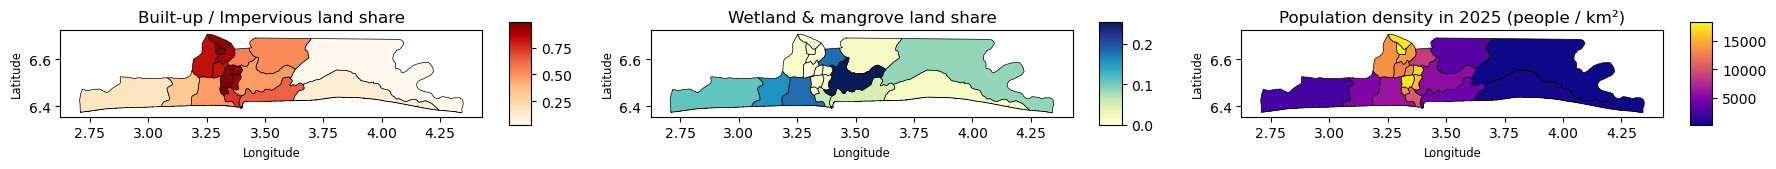

In [6]:
pop_2025 = pop_df[pop_df["year"] == 2025][["lga", "population", "pop_density_km2", "land_area_km2"]]
mapped = lagos.merge(landcover, on="lga").merge(pop_2025, on="lga")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
panels = [
    ("built_share", "Built-up / Impervious land share", "OrRd"),
    ("wetland_mangrove_share", "Wetland & mangrove land share", "YlGnBu"),
    ("pop_density_km2", "Population density in 2025 (people / km²)", "plasma"),
]
for ax, (col, title, cmap) in zip(axes, panels):
    mapped.plot(column=col, cmap=cmap, edgecolor="black", linewidth=0.5, legend=True, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
plt.tight_layout()
plt.show()

### Interpretation of Spatial Maps
The three maps highlight how urban flood risk in Lagos arises from two distinct spatial regimes:
1. **High-imperviousness, high-density urban core** (left and right panels): Central Lagos is almost completely paved (`built_share > 0.80`) and densely populated, generating rapid flash-flood runoff during intense downpours.
2. **Wetland and lagoon-fringe corridors** (middle panel): LGAs bordering the Lagos and Lekki Lagoons, Ogun River floodplain, and Badagry creek have high wetland/mangrove shares and low elevation, making them vulnerable to prolonged inundation and backwater locking.

## 6. Build the Master LGA-by-Month Dataset (`master_lga_month.csv`)

We now join all cleaned tables into the single master table required by the project work plan:
- **Target & event metadata** from `flood_labels_lga_month.csv` (3,840 rows)
- **Dynamic monthly & antecedent rainfall features** from `rainfall_lga_month.csv` (3,840 rows)
- **Static topographic & hydrological features** from `terrain_water_lga.csv` (20 rows)
- **Land cover shares** from `landcover_lga.csv` (20 rows)
- **Time-varying annual population & density** from `population_lga_year.csv` (320 rows)

We also engineer two physically meaningful **interaction features** that capture compound hydro-topographic mechanisms:
- `runoff_index = rain_total_mm * built_share`: Effective impervious surface runoff proxy (mm of rain falling directly on paved/built land).
- `coastal_Ponding_index = rain_max_3day_mm * low5_share`: Intense 3-day storm total falling on low-lying ground ($<5\text{ m}$ elevation).

In [7]:
labels = pd.read_csv(LABELS_PATH)
rain = pd.read_csv(RAIN_PATH)
terrain = pd.read_csv(TERRAIN_PATH)
lc = pd.read_csv(LANDCOVER_PATH)
pop = pd.read_csv(POP_PATH)

# Standardise merge keys
labels["month"] = pd.to_datetime(labels["month"]).dt.strftime("%Y-%m-%d")
rain["month"] = pd.to_datetime(rain["month"]).dt.strftime("%Y-%m-%d")

# Merge step-by-step with row-count verification
master = (
    labels[["lga", "month", "year", "month_num", "flood", "n_events", "max_severity", "sources"]]
    .merge(
        rain.drop(columns=["year", "month_num"]),
        on=["lga", "month"],
        how="inner",
        validate="one_to_one",
    )
    .merge(terrain, on="lga", how="left", validate="many_to_one")
    .merge(lc, on="lga", how="left", validate="many_to_one")
    .merge(pop, on=["lga", "year"], how="left", validate="many_to_one")
)

# Fill metadata columns for non-flood months cleanly
master["max_severity"] = master["max_severity"].fillna(0).astype(int)
master["sources"] = master["sources"].fillna("none")

# Engineer hydro-topographic interaction features
master["runoff_index"] = (master["rain_total_mm"] * master["built_share"]).round(2)
master["coastal_ponding_index"] = (master["rain_max_3day_mm"] * master["low5_share"]).round(2)

# Sort cleanly
master = master.sort_values(["lga", "month"]).reset_index(drop=True)

# Quality assertions
assert len(master) == 3840, f"Expected 3840 rows, found {len(master)}"
assert master["lga"].nunique() == 20, "Expected 20 unique LGAs"
assert master.duplicated(["lga", "month"]).sum() == 0, "Duplicate LGA-month rows found!"
assert master.isna().sum().sum() == 0, f"Unexpected nulls found: {master.isna().sum()[master.isna().sum() > 0].to_dict()}"

master.to_csv(MASTER_PATH, index=False)
print("Saved master dataset:", MASTER_PATH.resolve())
print(f"Shape: {master.shape[0]} rows x {master.shape[1]} columns")
print("Positive flood LGA-months:", master["flood"].sum(), f"({master['flood'].mean()*100:.2f}%)")
master.head()

Saved master dataset: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\master_lga_month.csv
Shape: 3840 rows x 40 columns
Positive flood LGA-months: 423 (11.02%)


,lga,month,year,month_num,flood,n_events,max_severity,sources,rain_total_mm,rain_max_daily_mm,...,bare_share,built_share,veg_share,wetland_mangrove_share,population,total_area_km2,land_area_km2,pop_density_km2,runoff_index,coastal_ponding_index
0,Agege,2010-01-01,2010,1,0,0,0,none,19.1,11.6,...,0.0,0.983,0.017,0.0,208387,16.49,16.49,12637.2,18.78,0.0
1,Agege,2010-02-01,2010,2,0,0,0,none,15.5,7.4,...,0.0,0.983,0.017,0.0,208387,16.49,16.49,12637.2,15.24,0.0
2,Agege,2010-03-01,2010,3,0,0,0,none,87.1,13.8,...,0.0,0.983,0.017,0.0,208387,16.49,16.49,12637.2,85.62,0.0
3,Agege,2010-04-01,2010,4,0,0,0,none,60.4,15.8,...,0.0,0.983,0.017,0.0,208387,16.49,16.49,12637.2,59.37,0.0
4,Agege,2010-05-01,2010,5,0,0,0,none,148.9,30.0,...,0.0,0.983,0.017,0.0,208387,16.49,16.49,12637.2,146.37,0.0


## 7. Generate the Data Dictionary (`data_dictionary.csv`)

Every column in `master_lga_month.csv` is documented below with its category, data type, physical unit, description, and primary data source.

In [8]:
data_dict_rows = [
    ("lga", "Identifier", "string", "-", "Official Local Government Area name (20 LGAs in Lagos State)", "GADM v4.1 (Level 2)"),
    ("month", "Identifier", "date (YYYY-MM-DD)", "month", "First day of the calendar month (2010-01-01 to 2025-12-01)", "Study grid"),
    ("year", "Temporal", "int", "year", "Calendar year (2010 to 2025)", "Derived from month"),
    ("month_num", "Temporal", "int", "1-12", "Calendar month number (1 = January, 12 = December)", "Derived from month"),
    ("flood", "Target", "binary int", "0 or 1", "1 if at least one credible source documents a flood in that LGA-month, else 0", "NEMA, LASEMA, NIHSA, EM-DAT, DFO/GFD, News Archive"),
    ("n_events", "Target metadata", "int", "count", "Number of distinct documented flood records affecting the LGA in that month", "Flood Events Log & DFO"),
    ("max_severity", "Target metadata", "int", "0-3 scale", "Maximum reported severity in that month (0=none, 1=street flood, 2=homes/roads submerged, 3=deaths/displacement)", "Flood Events Log"),
    ("sources", "Target metadata", "string", "-", "Source types documenting the flood in that LGA-month (or 'none')", "Flood Events Log"),
    ("rain_total_mm", "Rainfall (Dynamic)", "float", "mm", "Total monthly rainfall averaged across the LGA", "CHIRPS v2.0 Daily via GEE"),
    ("rain_max_daily_mm", "Rainfall (Dynamic)", "float", "mm/day", "Maximum single-day rainfall within the month", "CHIRPS v2.0 Daily via GEE"),
    ("rain_max_3day_mm", "Rainfall (Dynamic)", "float", "mm / 3 days", "Maximum 3-day rolling cumulative rainfall peaking in the month", "CHIRPS v2.0 Daily via GEE"),
    ("rain_max_7day_mm", "Rainfall (Dynamic)", "float", "mm / 7 days", "Maximum 7-day rolling cumulative rainfall peaking in the month", "CHIRPS v2.0 Daily via GEE"),
    ("rainy_days", "Rainfall (Dynamic)", "int", "days", "Number of days in the month with >= 1 mm rainfall", "CHIRPS v2.0 Daily via GEE"),
    ("heavy_rain_days", "Rainfall (Dynamic)", "int", "days", "Number of days in the month with >= 20 mm rainfall", "CHIRPS v2.0 Daily via GEE"),
    ("rain_prev_month_mm", "Rainfall (Antecedent)", "float", "mm", "Total rainfall in the immediately preceding month (soil saturation proxy)", "CHIRPS v2.0 Daily via GEE"),
    ("rain_2m_cum_mm", "Rainfall (Antecedent)", "float", "mm", "Cumulative two-month rainfall (current month + previous month)", "CHIRPS v2.0 Daily via GEE"),
    ("rain_anom_z", "Rainfall (Dynamic)", "float", "z-score (std)", "Standardised monthly rainfall anomaly relative to the LGA's 2010-2020 mean and std", "Derived from CHIRPS"),
    ("month_sin", "Temporal (Cyclical)", "float", "[-1, 1]", "Sine cyclical transform of month_num: sin(2*pi*m/12)", "Derived from month_num"),
    ("month_cos", "Temporal (Cyclical)", "float", "[-1, 1]", "Cosine cyclical transform of month_num: cos(2*pi*m/12)", "Derived from month_num"),
    ("elev_mean_m", "Terrain (Static)", "float", "metres (m)", "Mean land elevation above sea level (permanent water masked out)", "USGS SRTM 30m & JRC GSW via GEE"),
    ("elev_median_m", "Terrain (Static)", "float", "metres (m)", "Median land elevation above sea level", "USGS SRTM 30m via GEE"),
    ("elev_min_m", "Terrain (Static)", "float", "metres (m)", "Minimum land elevation in the LGA", "USGS SRTM 30m via GEE"),
    ("elev_max_m", "Terrain (Static)", "float", "metres (m)", "Maximum land elevation in the LGA", "USGS SRTM 30m via GEE"),
    ("elev_std_m", "Terrain (Static)", "float", "metres (m)", "Standard deviation of land elevation in the LGA", "USGS SRTM 30m via GEE"),
    ("low5_share", "Terrain (Static)", "float", "proportion [0-1]", "Fraction of LGA land area lying below 5 metres elevation", "USGS SRTM 30m via GEE"),
    ("low10_share", "Terrain (Static)", "float", "proportion [0-1]", "Fraction of LGA land area lying below 10 metres elevation", "USGS SRTM 30m via GEE"),
    ("slope_mean_deg", "Terrain (Static)", "float", "degrees", "Mean topographic slope across land pixels in the LGA", "USGS SRTM 30m via GEE"),
    ("water_share", "Hydrology (Static)", "float", "proportion [0-1]", "Fraction of total LGA area covered by permanent water (lagoon, creeks, sea)", "JRC Global Surface Water v1.4 (30m)"),
    ("dist_water_mean_km", "Hydrology (Static)", "float", "kilometres (km)", "Mean Euclidean distance from land pixels to nearest permanent water body", "JRC Global Surface Water v1.4 (150m grid)"),
    ("near_water_1km_share", "Hydrology (Static)", "float", "proportion [0-1]", "Fraction of LGA land area within 1 km of permanent water", "JRC Global Surface Water v1.4"),
    ("built_share", "Land Cover (Static)", "float", "proportion [0-1]", "Fraction of LGA land area classified as built-up / impervious surface (Class 50)", "ESA WorldCover v200 (10m)"),
    ("wetland_mangrove_share", "Land Cover (Static)", "float", "proportion [0-1]", "Fraction of LGA land area classified as herbaceous wetland or mangrove (Classes 90, 95)", "ESA WorldCover v200 (10m)"),
    ("veg_share", "Land Cover (Static)", "float", "proportion [0-1]", "Fraction of LGA land area covered by trees, shrubland, grassland, or crops (Classes 10-40)", "ESA WorldCover v200 (10m)"),
    ("bare_share", "Land Cover (Static)", "float", "proportion [0-1]", "Fraction of LGA land area classified as bare or sparse vegetation (Class 60)", "ESA WorldCover v200 (10m)"),
    ("population", "Exposure (Annual)", "int", "persons", "Estimated annual resident population of the LGA (2010-2025)", "WorldPop 100m (R2025A & legacy harmonised)"),
    ("total_area_km2", "Geometry (Static)", "float", "km^2", "Total geographic area of the LGA polygon (land + internal water)", "GADM v4.1 (EPSG:32631)"),
    ("land_area_km2", "Geometry (Static)", "float", "km^2", "Effective land area of the LGA excluding permanent water", "GADM v4.1 & JRC Water Mask"),
    ("pop_density_km2", "Exposure (Annual)", "float", "persons / km^2", "Annual population density per square kilometre of land area", "WorldPop & Land Area"),
    ("runoff_index", "Interaction Feature", "float", "mm", "Impervious surface runoff proxy: rain_total_mm * built_share", "Engineered (CHIRPS x WorldCover)"),
    ("coastal_ponding_index", "Interaction Feature", "float", "mm", "Low-lying storm accumulation proxy: rain_max_3day_mm * low5_share", "Engineered (CHIRPS x SRTM)"),
]

dict_df = pd.DataFrame(
    data_dict_rows,
    columns=["column_name", "category", "dtype", "unit", "description", "source"]
)

# Confirm every column in master is documented and reorder dict_df to match master.columns
assert set(dict_df["column_name"]) == set(master.columns), (
    f"Mismatch between data dictionary and master columns: {set(dict_df['column_name']) ^ set(master.columns)}"
)
dict_df = dict_df.set_index("column_name").loc[list(master.columns)].reset_index()

dict_df.to_csv(DICT_PATH, index=False)
print("Saved data dictionary:", DICT_PATH.resolve())
display(dict_df)

Saved data dictionary: C:\Users\LENOVO\Desktop\Portfolio Projects\lagos-flood-risk-ml\data\clean\data_dictionary.csv


,column_name,category,dtype,unit,description,source
0,lga,Identifier,string,-,Official Local Government Area name (20 LGAs i...,GADM v4.1 (Level 2)
1,month,Identifier,date (YYYY-MM-DD),month,First day of the calendar month (2010-01-01 to...,Study grid
2,year,Temporal,int,year,Calendar year (2010 to 2025),Derived from month
3,month_num,Temporal,int,1-12,"Calendar month number (1 = January, 12 = Decem...",Derived from month
4,flood,Target,binary int,0 or 1,1 if at least one credible source documents a ...,"NEMA, LASEMA, NIHSA, EM-DAT, DFO/GFD, News Arc..."
5,n_events,Target metadata,int,count,Number of distinct documented flood records af...,Flood Events Log & DFO
6,max_severity,Target metadata,int,0-3 scale,Maximum reported severity in that month (0=non...,Flood Events Log
7,sources,Target metadata,string,-,Source types documenting the flood in that LGA...,Flood Events Log
8,rain_total_mm,Rainfall (Dynamic),float,mm,Total monthly rainfall averaged across the LGA,CHIRPS v2.0 Daily via GEE
9,rain_max_daily_mm,Rainfall (Dynamic),float,mm/day,Maximum single-day rainfall within the month,CHIRPS v2.0 Daily via GEE


## Summary & Conclusion

1. **Land Cover (`data/clean/landcover_lga.csv`)**: Extracted 10 m **ESA WorldCover v200** shares across all 20 Lagos LGAs. Metropolitan LGAs (e.g., Mushin, Ajeromi/Ifelodun, Agege, Lagos Island, Shomolu, Surulere) exceed 80–95% impervious built-up land cover, while lagoon-fringe LGAs contain extensive wetland and mangrove zones.
2. **Population & Exposure (`data/clean/population_lga_year.csv`)**: Extracted and harmonised **WorldPop 100 m** annual population estimates from 2010 to 2025 (320 LGA-years), capturing both high inner-city densities and rapid suburban/coastal population growth.
3. **Master Dataset (`data/clean/master_lga_month.csv`)**: Assembled all 3,840 LGA-month records (20 LGAs $\times$ 192 months) with **40 columns**, zero missing values, and a fully verified **Data Dictionary (`data/clean/data_dictionary.csv`)**.
4. **Phase 2 Complete**: All requirements for Phase 2 of the Work Plan are now fulfilled. Next, **`06_eda.ipynb`** explores the spatial, seasonal, and physical relationships driving flood occurrence across Lagos State.